# Predicting bit score and tRNA

Continuing with the RNA family dataset from last week.

This time I'll use linear regression to predict a number (bit score) and logistic regression to predict yes or no (is it a tRNA).

Length ends up predicting both targets decently, but the base makeup alone doesn't.

<font color="red">I am using Rfam release 15.1. The PDB sequence file is updated weekly, so counts from that side could shift slightly. These numbers come from the October 2026 PDB version.</font>

# 1. Load the clean data
Look back at last week's notebook for more detail on the cleaning steps. The only change is that I kept bit_score this time instead of dropping it.

In [1]:
import pandas as pd

# Rfam's mapping of PDB chains to RNA families
rfam = pd.read_csv("https://ftp.ebi.ac.uk/pub/databases/Rfam/15.1/Rfam.pdb.gz",
                   sep="\t", header=None,
                   names=["rfam_acc", "pdb_id", "chain", "pdb_start", "pdb_end",
                          "bit_score", "evalue", "cm_start", "cm_end", "hex_colour"])

# every chain sequence in PDB
lines = pd.read_csv("https://files.wwpdb.org/pub/pdb/derived_data/pdb_seqres.txt.gz",
                    sep="\t", header=None, names=["line"], quoting=3)

# split lines into headers and sequences
is_header = lines["line"].str.startswith(">")
headers = lines[is_header == True].reset_index(drop=True)
sequences = lines[is_header == False].reset_index(drop=True)
seqs = headers.copy()
seqs["sequence"] = sequences["line"]

# keep only nucleic acids, then take PDB ID, chain, and molecule name out of header
seqs = seqs[seqs["line"].str.contains("mol:na")]
parts = seqs["line"].str.split(" ", n=3, expand=True)
ids = parts[0].str.replace(">", "").str.split("_", expand=True)
seqs["pdb_id"] = ids[0]
seqs["chain"] = ids[1]
seqs["molecule_name"] = parts[3].str.strip()
seqs = seqs.drop(columns = ["line"])

# join on pdb_id and chain, and calculate chain coverage
join = pd.merge(seqs, rfam, on=["pdb_id", "chain"], how="inner")
join["coverage"] = (join["pdb_end"]-join["pdb_start"]+1)/join["sequence"].str.len()

# drop unnecessary columns (keeping bit_score this time)
clean = join.drop(columns=["pdb_start", "pdb_end", "evalue", "cm_start", "cm_end", "hex_colour"])

# remove multi family chains
clean = clean.drop_duplicates(subset=["pdb_id", "chain", "rfam_acc"])
clean = clean[~clean.duplicated(subset=["pdb_id", "chain"], keep=False)]

# coverage cutoff
clean = clean[clean["coverage"] >= 0.8]

# DNA and nonstandard characters
clean["frac"] = clean["sequence"].str.replace("[AUCG]", "", regex=True).str.len() / clean["sequence"].str.len()
clean = clean[clean["frac"] <= 0.06]
clean["sequence"] = clean["sequence"].str.replace("T", "U")   # ribothymidine
clean["sequence"] = clean["sequence"].str.replace("I", "A")   # inosine
clean["sequence"] = clean["sequence"].str.replace("[^AUCG]", "", regex=True)
clean = clean.drop(columns=["frac"])

# deduplicate sequences
clean = clean.drop_duplicates(subset=["sequence"])

# 20 example minimum
keep = clean["rfam_acc"].value_counts()[clean["rfam_acc"].value_counts() >= 20].index
clean = clean[clean["rfam_acc"].isin(keep)]

# fix index
clean = clean.reset_index(drop=True)
clean.shape

(1456, 7)

Same as last week, 1456 distinct sequences across 11 families, plus the bit_score column.

# 2. Choose targets

bit_score means how strongly a sequence matches its family's Rfam model, and higher means a stronger match. Rfam calculates it with the family's model, so you can't get it just by counting letters.

<Axes: >

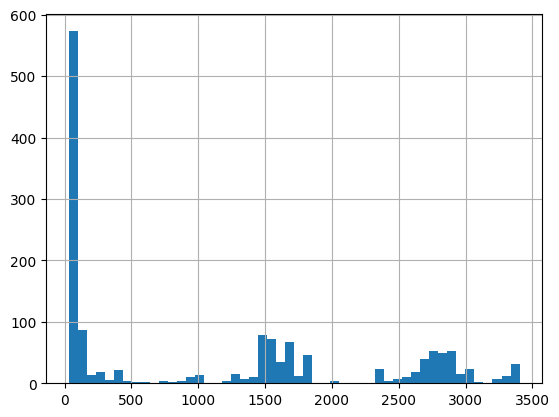

In [2]:
clean["bit_score"].hist(bins=50)

Most bit scores are either relatively small (<150 ish) or large (in the thousands), with not much in between. The low ones are the short families like tRNA and 5S rRNA, and the high ones are the big rRNAs (ribosomal).

For logistic regression I'm predicting whether a sequence is a tRNA (transfer RNA, family RF00005).

== "RF00005" gives True or False for each sequence, and astype(int) turns that into 1 and 0.

In [3]:
clean["trna"] = (clean["rfam_acc"] == "RF00005").astype(int)
clean["trna"].value_counts()

,count
trna,
0,1063
1,393


393 of the 1456 sequences are tRNA (~ 27%). So a model that just always says "not tRNA" would already be right 73% of the time.

# 3. Choose features

In [4]:
# length of each sequence
clean["length"] = clean["sequence"].str.len()

# fraction of each sequence that is each base
clean["frac_A"] = clean["sequence"].str.count("A") / clean["length"]
clean["frac_U"] = clean["sequence"].str.count("U") / clean["length"]
clean["frac_C"] = clean["sequence"].str.count("C") / clean["length"]
clean["frac_G"] = clean["sequence"].str.count("G") / clean["length"]

features = ["frac_A", "frac_U", "frac_C", "frac_G"]
clean[["length"] + features].head()

,length,frac_A,frac_U,frac_C,frac_G
0,75,0.173333,0.253333,0.253333,0.320000
1,74,0.216216,0.216216,0.283784,0.283784
2,58,0.327586,0.224138,0.189655,0.258621
3,77,0.142857,0.220779,0.285714,0.350649
4,2904,0.262397,0.203512,0.220386,0.313705


The features have to be numbers, so I turned each sequence into its length and the fraction that is A, U, C and G.

I used fractions instead of raw counts so that the base makeup is independent from the length (long sequences obviously have way more raw # of bases).

I left out evalue since it would basically leak the bit score, rfam_acc since it would leak the family, coverage since it doesn't add anything helpful, and length for the tRNA model since tRNAs are all ~76 long so the model could just check length (I'll add it back at the end).

# 4. Train both models

## Part 1: Bit score from length

A longer match should give a higher bit score, since there's more sequence to match the family model.

<Axes: xlabel='length', ylabel='bit_score'>

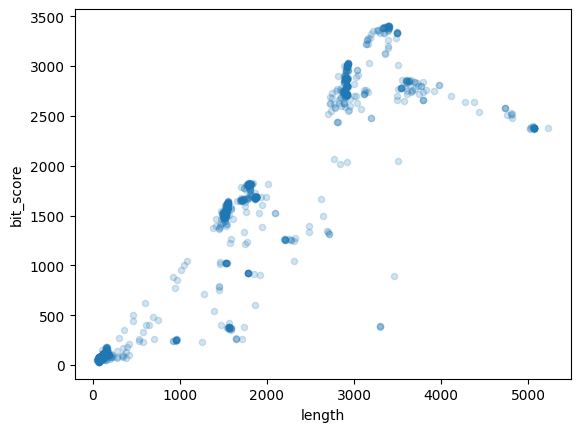

In [5]:
clean.plot.scatter(x="length", y="bit_score", alpha=0.2)

The dots go up in a decently straight band from left to right, so longer sequences have higher bit scores.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X = clean[["length"]]
y = clean["bit_score"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
model.coef_, model.intercept_

(array([0.79350409]), np.float64(73.13908025009641))

The line is roughly

bit_score = 0.79 * length + 73

Each extra nucleotide adds about 0.8 to the bit score.

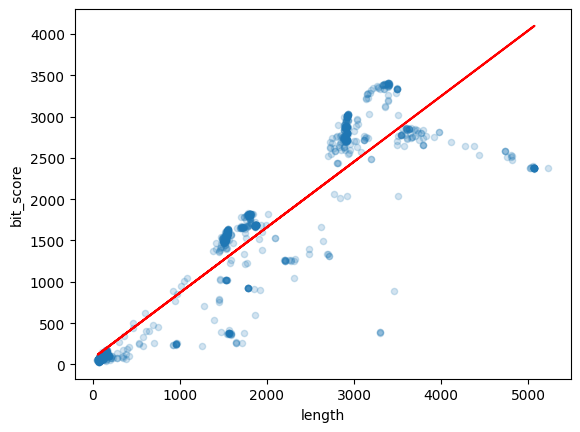

In [7]:
pred = model.predict(X_test)

ax = clean.plot.scatter(x="length", y="bit_score", alpha=0.2)
ax.plot(X_test["length"], pred, color="red")

In [8]:
from sklearn.metrics import mean_absolute_error, r2_score

print(mean_absolute_error(y_test, pred))
print(r2_score(y_test, pred))

233.37167087370537
0.9091915034853308


The MAE is about 233, so predictions are off by about 233 on average, on a scale from about 30 to 3400.

The R² is about 0.91, so length explains most of the bit score.

## Part 2: Bit score from base makeup

Can the bases alone predict bit score without length?

In [9]:
X = clean[features]
y = clean["bit_score"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)

print(mean_absolute_error(y_test, pred))
print(r2_score(y_test, pred))

759.3049880331099
0.35635211604527817


Much worse.

The MAE is about 759 and the R² is about 0.36. The bases only explain some of the bit score. This is probably because big rRNAs and small RNAs have slightly different base makeups, but the bases can't tell how long the sequence is.

Every bit score in the data is above 30, but what does the model predict?

In [10]:
print((pred < 0).sum())
pred.min()

9


np.float64(-907.1611142647728)

The model predictts 9 test sequences to have a negative bit score, and the lowest is about -907, which is nonsensical.

## Part 3: Is it a tRNA?

Is the base fraction even different for tRNA and non tRNA?

In [11]:
clean.groupby("trna")[features].mean()

,frac_A,frac_U,frac_C,frac_G
trna,,,,
0,0.246534,0.208519,0.243838,0.301108
1,0.206703,0.207484,0.279492,0.306322


There's some difference in A (about 0.25 vs 0.21) and C (about 0.24 vs 0.28), but U and G are almost the same.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

X = clean[features]
y = clean["trna"]

X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(X, y, test_size=0.2, random_state=42)

model_t = LogisticRegression(max_iter=1000)
model_t.fit(X_train_t, y_train_t)
pred_t = model_t.predict(X_test_t)

accuracy_score(y_test_t, pred_t)

0.708904109589041

I trained all three models on 80% of the data and scored them on the other 20%. Length predicts bit score pretty well, but the bases alone do much worse. The tRNA model gets about 71% accuracy, but that still needs to be compared to a lazy guess.

# 5. Compare to a lazy guess

In [13]:
# always guess the average bit score
avg = y_train.mean()
mean_absolute_error(y_test, [avg] * len(y_test))

1042.589279998117

About 1043 for the lazy guess.
The length model (233) beats it by a lot, but the base makeup model (759) beats it by less.

In [14]:
# always guess "not tRNA"
(y_test_t == 0).mean()

np.float64(0.708904109589041)

In [15]:
confusion_matrix(y_test_t, pred_t)

array([[207,   0],
       [ 85,   0]])

In [16]:
recall_score(y_test_t, pred_t)

0.0

The accuracy is exactly the same as always guessing "not tRNA" (0.709). The right column of the confusion matrix is all zeros, so the model never predicts tRNA. Recall is 0, it found none of the 85 tRNAs in the test set, and precision can't be calculated since it never says yes.

# 6. Try other thresholds

predict says tRNA only when the chance is 0.5 or more.

In [17]:
proba = model_t.predict_proba(X_test_t)[:, 1]
proba.max()

np.float64(0.46093353153837546)

The highest chance any test sequence gets is about 0.46, which is below 0.5, so the model never says tRNA.

proba >= 0.3 gives True or False for each sequence, and astype(int) turns it into numbers.

In [18]:
pred_t = (proba >= 0.3).astype(int)

print(confusion_matrix(y_test_t, pred_t))
print(accuracy_score(y_test_t, pred_t))
print(precision_score(y_test_t, pred_t))
print(recall_score(y_test_t, pred_t))

[[175  32]
 [ 32  53]]
0.7808219178082192
0.6235294117647059
0.6235294117647059


In [19]:
pred_t = (proba >= 0.2).astype(int)

print(confusion_matrix(y_test_t, pred_t))
print(accuracy_score(y_test_t, pred_t))
print(precision_score(y_test_t, pred_t))
print(recall_score(y_test_t, pred_t))

[[ 39 168]
 [  4  81]]
0.410958904109589
0.3253012048192771
0.9529411764705882


In [20]:
pred_t = (proba >= 0.35).astype(int)

print(confusion_matrix(y_test_t, pred_t))
print(accuracy_score(y_test_t, pred_t))
print(precision_score(y_test_t, pred_t))
print(recall_score(y_test_t, pred_t))

[[192  15]
 [ 59  26]]
0.7465753424657534
0.6341463414634146
0.3058823529411765


At 0.2 it finds about 95% of the tRNAs, but only about a third of what it calls tRNA actually is, and accuracy drops to 0.41. At 0.35 precision is about 0.63, but recall drops to about 0.31.

I would use 0.3, since it's the only one where accuracy (0.78) is better than the lazy guess of 0.71, and precision and recall are decently balanced at about 0.62 each.

# 7. Explain results

What happens if length is added to the tRNA model?

In [21]:
X = clean[features + ["length"]]
y = clean["trna"]

X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(X, y, test_size=0.2, random_state=42)

model_t = LogisticRegression(max_iter=1000)
model_t.fit(X_train_t, y_train_t)
pred_t = model_t.predict(X_test_t)

print(confusion_matrix(y_test_t, pred_t))
print(accuracy_score(y_test_t, pred_t))
print(precision_score(y_test_t, pred_t))
print(recall_score(y_test_t, pred_t))

[[197  10]
 [  1  84]]
0.9623287671232876
0.8936170212765957
0.9882352941176471


With length it gets 0.96 accuracy even at the normal 0.5 threshold and finds 84 of the 85 tRNAs.

Linear regression worked with length (R² 0.91, MAE 233 vs 1043 for the lazy guess). Bit score goes up by about 0.8 for every nucleotide, so it mostly measures how big the match is. The base makeup alone didn't work very well (R² 0.36) and predicted impossible negative bit scores, because the bases can't tell how long a sequence is.

Logistic regression on the bases alone didn't work at the default threshold and never predicted any tRNA. Lowering the threshold to 0.3 made it work better, but only a bit better than guessing. Adding length made it work very well, but this is only because tRNAs are much shorter than everything else.

In both models, length did most of the work and the base fractions added very little. Last week, the k-mer random forest got 0.98 across all 11 families. Using four fractions basically throws away all the information given by the order of the letters, which is probably a big part of why they do so much worse.